<a href="https://colab.research.google.com/github/petersonrs/petersonrs/blob/main/An%C3%A1lise_Nivel_Rios.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## ANALISE

"""
Leitura e análise do histórico de nível de rio salvo em Parquet.

Adaptado para a estrutura de pastas usada no Google Colab, com um arquivo
por estação DENTRO de cada pasta de data, por exemplo:

    /content/drive/MyDrive/Python/Analise Volume Rio/parquet/2026/09/25/nivel_rio_dc06.parquet
    /content/drive/MyDrive/Python/Analise Volume Rio/parquet/2026/09/26/nivel_rio_dc06.parquet
    ...

Como os arquivos ficam espalhados em várias pastas (uma por dia), a leitura
usa glob recursivo (`**/*.parquet`) para achar todos os arquivos de uma
estação/tipo e depois concatena tudo num único DataFrame.

USO RÁPIDO (dentro do Colab/Jupyter):

    from analisar_historico import ler_historico
    df = ler_historico("DC06")
    print(df.tail())

Funções disponíveis:
  - ler_historico(estacao_codigo, tipo="nivel_rio")   -> uma estação, todas as datas
  - ler_todas_estacoes(tipo="nivel_rio")               -> todas as estações, todas as datas
  - filtrar_periodo(df, ultimas_horas=24)              -> recorta uma janela de tempo
  - detectar_acima_do_limite(df, nivel_limite_m=2.0)   -> leituras acima de uma cota
  - resumo_diario(df)                                  -> min/max/média por dia

`tipo` pode ser:
  - "nivel_rio"        -> arquivos nivel_rio_<codigo>.parquet (nível simples)
  - "dados_completos"  -> arquivos dados_completos_<codigo>.parquet (nível + chuva + variação)
"""

In [7]:
from pathlib import Path
from datetime import datetime, timedelta

import pandas as pd

# Ajuste este caminho se você mudar a estrutura de pastas no Drive.
BASE_PARQUET_DIR = Path("/content/drive/MyDrive/Python/Analise Volume Rio/parquet")



In [8]:
def _ler_arquivos(padrao_nome: str, dias_atras: int = None) -> pd.DataFrame:
    """Busca recursivamente por arquivos que batam com o padrão informado.
    Se `dias_atras` for definido, filtra as pastas apenas dos últimos N dias."""
    if dias_atras is not None:
        hoje = datetime.now()
        datas_permitidas = {(hoje - timedelta(days=i)).strftime("%Y/%m/%d") for i in range(dias_atras + 1)}

        arquivos = []
        for arquivo in BASE_PARQUET_DIR.glob(f"**/{padrao_nome}"):
            partes_caminho = "/".join(arquivo.parts)
            if any(dt in partes_caminho for dt in datas_permitidas):
                arquivos.append(arquivo)
    else:
        arquivos = list(BASE_PARQUET_DIR.glob(f"**/{padrao_nome}"))

    if not arquivos:
        raise FileNotFoundError(
            f"Nenhum arquivo '{padrao_nome}' encontrado em {BASE_PARQUET_DIR} para o período selecionado."
        )

    dfs = [pd.read_parquet(arquivo) for arquivo in arquivos]
    df = pd.concat(dfs, ignore_index=True)

    chave = [c for c in ["estacao_codigo", "data_hora_medicao"] if c in df.columns]
    if chave:
        df = df.drop_duplicates(subset=chave, keep="last")

    return df


def ler_historico(estacao_codigo: str, tipo: str = "dados_completos", dias_atras: int = None) -> pd.DataFrame:
    """Lê e junta os parquets de uma estação, filtrando opcionalmente por dias_atras."""
    padrao = f"{tipo}_{estacao_codigo.lower()}.parquet"
    df = _ler_arquivos(padrao, dias_atras=dias_atras)
    return df.sort_values(by='data_hora_medicao', ascending=True).reset_index(drop=True)


def ler_todas_estacoes(tipo: str = "dados_completos", dias_atras: int = None) -> pd.DataFrame:
    """Lê e junta os parquets de TODAS as estações filtrando opcionalmente por dias_atras."""
    padrao = f"{tipo}_*.parquet"
    df = _ler_arquivos(padrao, dias_atras=dias_atras)
    return df.sort_values(["estacao_codigo", "data_hora_medicao"], ascending=True).reset_index(drop=True)


def filtrar_periodo(df: pd.DataFrame, inicio: datetime = None, fim: datetime = None, ultimas_horas: int = None) -> pd.DataFrame:
    """Filtra o DataFrame por período de horas ou datas."""
    if ultimas_horas is not None:
        limite = df["data_hora_medicao"].max() - timedelta(hours=ultimas_horas)
        return df[df["data_hora_medicao"] >= limite]

    resultado = df
    if inicio is not None:
        resultado = resultado[resultado["data_hora_medicao"] >= inicio]
    if fim is not None:
        resultado = resultado[resultado["data_hora_medicao"] <= fim]
    return resultado


def detectar_acima_do_limite(df: pd.DataFrame, nivel_limite_m: float) -> pd.DataFrame:
    """Retorna as leituras acima ou iguais ao limite estipulado."""
    return df[df["nivel_m"] >= nivel_limite_m].sort_values("data_hora_medicao", ascending=True)


def resumo_diario(df: pd.DataFrame) -> pd.DataFrame:
    """Agrupa por dia e mostra as estatísticas básicas."""
    temp = df.sort_values(by='data_hora_medicao', ascending=True).copy()
    temp["data"] = temp["data_hora_medicao"].dt.date
    return temp.groupby("data")["nivel_m"].agg(["min", "max", "mean"]).round(2)

--- ÚLTIMAS MEDIÇÕES REGISTRADAS ---
                                                estacao_descricao  \
estacao_codigo                                                      
DC06            DC06 Rio Itajaí-Mirim (curso antigo) - Itamiri...   
DC09            DC09 Ribeirão da Murta - Ponte da Rua Lidia Pu...   
DC10                      DC10 Rio Itajaí-Mirim – Bairro Limoeiro   
DCSC-00019                                 Estação MKS DCSC-00019   

                 data_hora_medicao  nivel_m  
estacao_codigo                               
DC06           2026-11-09 08:40:00     0.68  
DC09           2026-11-09 08:50:00     1.08  
DC10           2026-11-09 08:40:00     4.72  
DCSC-00019     2026-11-09 08:50:00     2.23  


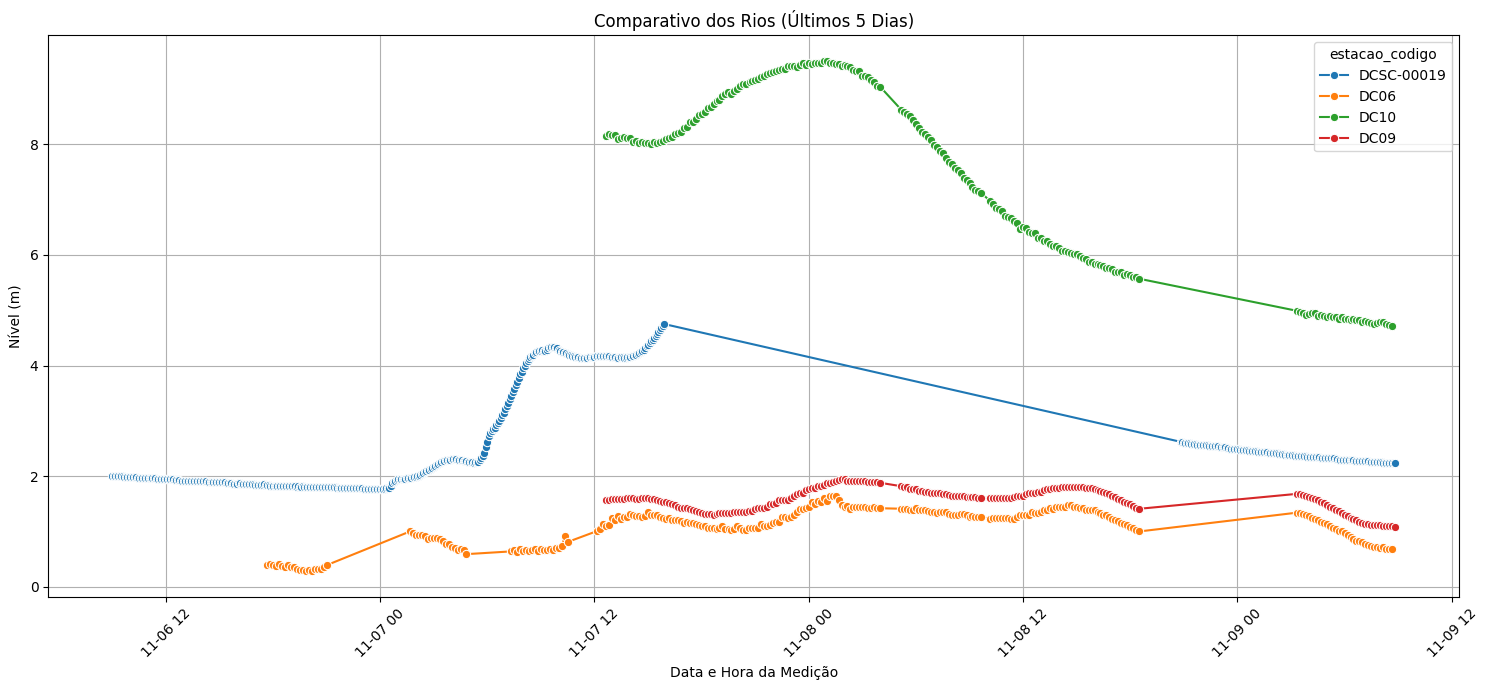

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Exemplo de uso para ler apenas os últimos 5 dias das estações
estacoes = ['DC09','DC10','DC06','DCSC-00019']
dfs = []

for est in estacoes:
    try:
        # Passando o novo parâmetro opcional 'dias_atras' para otimizar a leitura
        temp_df = ler_historico(est, tipo='dados_completos', dias_atras=2)
        dfs.append(temp_df)
    except Exception:
        try:
            temp_df = ler_historico(est, tipo='nivel_rio', dias_atras=2)
            dfs.append(temp_df)
        except Exception as e:
            print(f"Não foi possível carregar os dados da estação {est}: {e}")

if dfs:
    df_analise = pd.concat(dfs, ignore_index=True)

    print("--- ÚLTIMAS MEDIÇÕES REGISTRADAS ---")
    ultimas_medicoes = df_analise.sort_values('data_hora_medicao').groupby('estacao_codigo').last()
    print(ultimas_medicoes[['estacao_descricao', 'data_hora_medicao', 'nivel_m']])

    plt.figure(figsize=(15, 7))
    sns.lineplot(
        data=df_analise.sort_values(by='data_hora_medicao'),
        x='data_hora_medicao',
        y='nivel_m',
        hue='estacao_codigo',
        marker='o'
    )

    plt.title('Comparativo dos Rios (Últimos 5 Dias)')
    plt.xlabel('Data e Hora da Medição')
    plt.ylabel('Nível (m)')
    plt.grid(True)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("Nenhum dado encontrado para as estações solicitadas.")

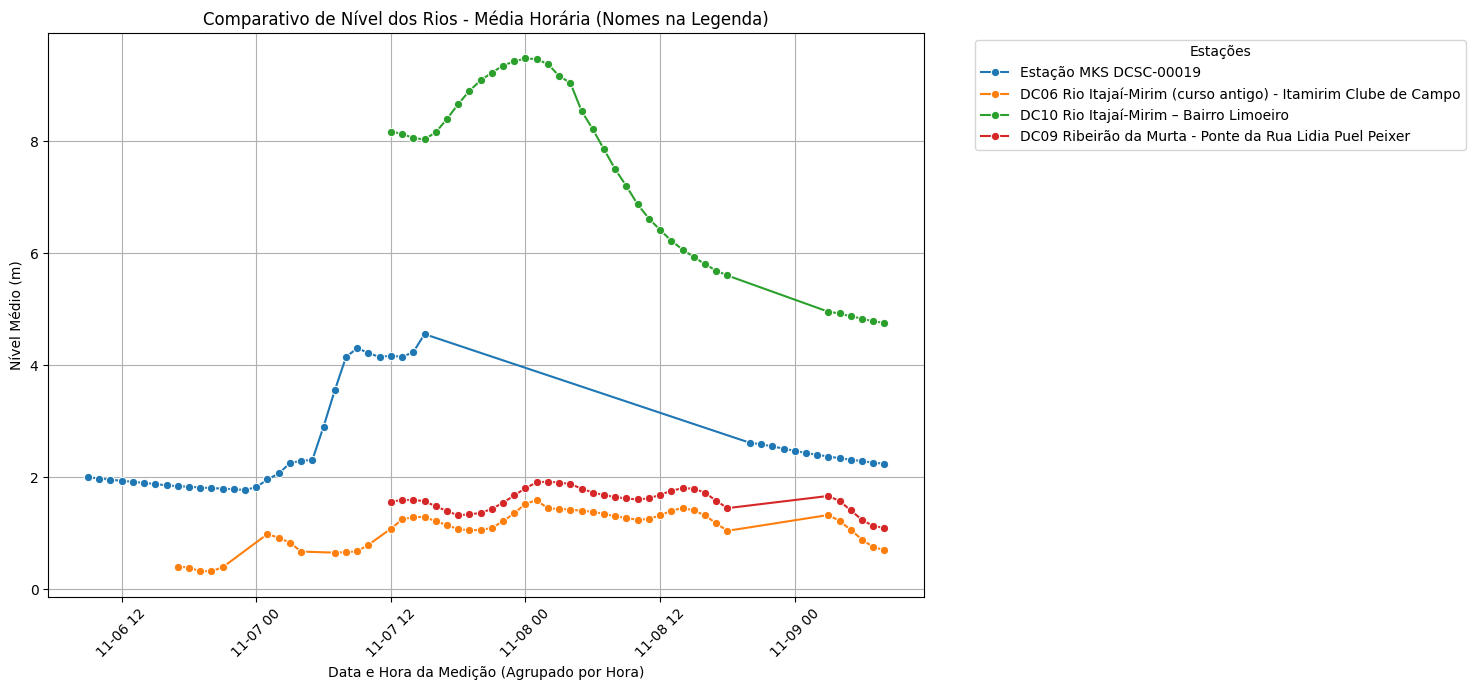

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

if 'df_analise' in globals() and not df_analise.empty:
    df_hourly = df_analise.copy()

    # Garante que está em formato datetime
    df_hourly['data_hora_medicao'] = pd.to_datetime(df_hourly['data_hora_medicao'])

    # Agrupa por hora e pela descrição da estação (nome do rio) para a legenda
    df_resampled = df_hourly.groupby([
        pd.Grouper(key='data_hora_medicao', freq='h'),
        'estacao_descricao'
    ])['nivel_m'].mean().reset_index()

    # Plotar gráfico de linha com o nome das estações na legenda
    plt.figure(figsize=(15, 7))
    sns.lineplot(
        data=df_resampled.sort_values(by='data_hora_medicao'),
        x='data_hora_medicao',
        y='nivel_m',
        hue='estacao_descricao',
        marker='o'
    )

    plt.title('Comparativo de Nível dos Rios - Média Horária (Nomes na Legenda)')
    plt.xlabel('Data e Hora da Medição (Agrupado por Hora)')
    plt.ylabel('Nível Médio (m)')
    plt.grid(True)
    plt.xticks(rotation=45)

    # Ajusta a legenda para não cortar o texto longo das estações
    plt.legend(title='Estações', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()
else:
    print("DataFrame 'df_analise' não encontrado. Por favor, execute a célula que carrega os dados primeiro.")